In [1]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
RESULT_DIR = PROJECT_DIR / "results"

RESULT_DIR.mkdir(exist_ok=True)

DEVICE = torch.device("cpu")

print("Device:", DEVICE)
print("Project directory:", PROJECT_DIR)

Device: cpu
Project directory: C:\B.tech\Project\Fetal_Ultrasound_Project


In [2]:
CSV_PATH = DATA_DIR / "FETAL_PLANES_DB_data.csv"
IMAGE_DIR = DATA_DIR / "Images"

df = pd.read_csv(CSV_PATH, sep=";")
df.columns = df.columns.str.strip()

test_df = df[df["Train"] == 0].copy()

class_names = sorted(df["Plane"].unique())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

print("Test images:", len(test_df))
print("Number of classes:", len(class_names))
print("\nClasses:", class_names)
print("\nTest class distribution:")
print(test_df["Plane"].value_counts())

Test images: 5271
Number of classes: 6

Classes: ['Fetal abdomen', 'Fetal brain', 'Fetal femur', 'Fetal thorax', 'Maternal cervix', 'Other']

Test class distribution:
Plane
Other              1612
Fetal brain        1472
Fetal thorax        660
Maternal cervix     645
Fetal femur         524
Fetal abdomen       358
Name: count, dtype: int64


In [3]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Test transformations created successfully!")

Test transformations created successfully!


In [4]:
class FetalTestDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = self.image_dir / f"{row['Image_name']}.png"

        image = Image.open(image_path).convert("RGB")

        label = class_to_idx[row["Plane"]]

        if self.transform:
            image = self.transform(image)

        return image, label


test_dataset = FetalTestDataset(
    test_df,
    IMAGE_DIR,
    test_transform
)

print("Test dataset size:", len(test_dataset))

Test dataset size: 5271


In [5]:
test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(test_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])


In [6]:
MODEL_PATH = MODEL_DIR / "resnet18_baseline_best.pth"

model = models.resnet18(weights=None)

model.fc = torch.nn.Linear(
    model.fc.in_features,
    len(class_names)
)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE
)

# Support both checkpoint formats
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model = model.to(DEVICE)
model.eval()

print("ResNet18 model loaded successfully!")
print("Model:", MODEL_PATH)

ResNet18 model loaded successfully!
Model: C:\B.tech\Project\Fetal_Ultrasound_Project\models\resnet18_baseline_best.pth


In [7]:
all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

print("Predictions completed!")
print("Total predictions:", len(all_predictions))
print("Total actual labels:", len(all_labels))

Predictions completed!
Total predictions: 5271
Total actual labels: 5271


In [8]:
test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 93.72%


In [9]:
report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

                 precision    recall  f1-score   support

  Fetal abdomen     0.8828    0.9050    0.8938       358
    Fetal brain     0.9912    0.9959    0.9936      1472
    Fetal femur     0.8652    0.9065    0.8854       524
   Fetal thorax     0.8675    0.9621    0.9124       660
Maternal cervix     0.9954    0.9969    0.9961       645
          Other     0.9326    0.8666    0.8984      1612

       accuracy                         0.9372      5271
      macro avg     0.9224    0.9388    0.9299      5271
   weighted avg     0.9384    0.9372    0.9371      5271



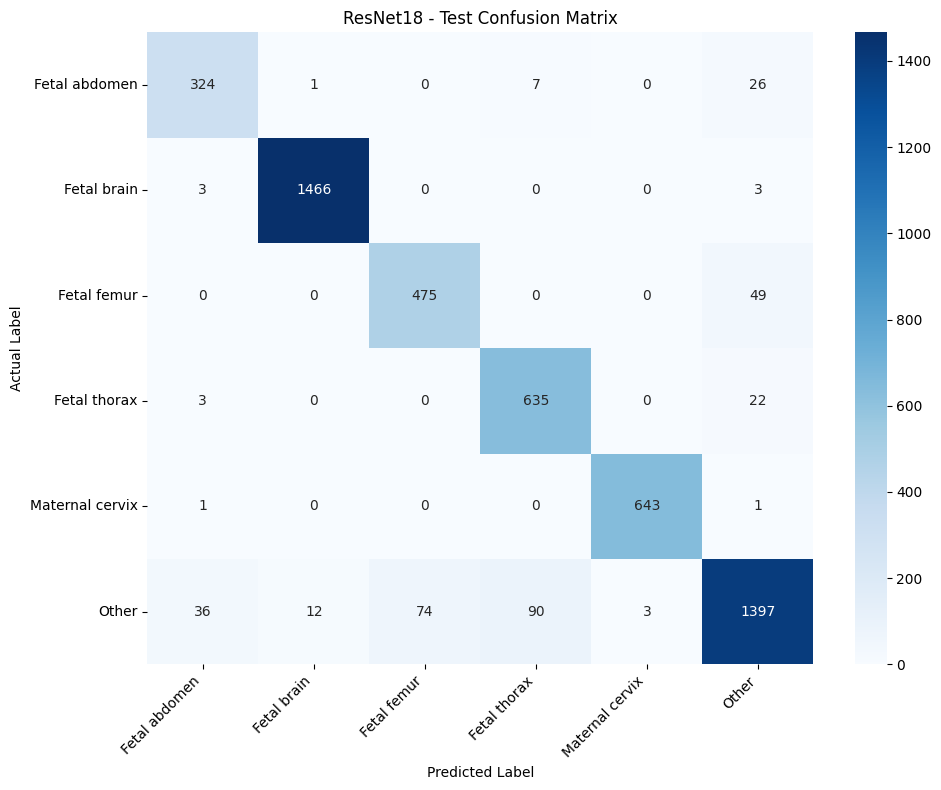

In [10]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ResNet18 - Test Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "baseline_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
evaluation_df = pd.DataFrame({
    "Actual": [class_names[i] for i in all_labels],
    "Predicted": [class_names[i] for i in all_predictions]
})

evaluation_df.to_csv(
    RESULT_DIR / "baseline_test_predictions.csv",
    index=False
)

report_dict = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    RESULT_DIR / "baseline_classification_report.csv"
)

print("Evaluation results saved successfully!")
print("Files saved in:", RESULT_DIR)

Evaluation results saved successfully!
Files saved in: C:\B.tech\Project\Fetal_Ultrasound_Project\results
